# M04 Overview | Conv + BN Folding: PTQ Folds at prepare, QAT Folds Only at convert

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m04_conv_bn_folding/00_overview.ipynb)

Almost every conv in a model is followed by a BatchNorm. At deployment the BN does not run on its own: its computation can be folded entirely into the preceding conv.
This chapter looks at which step PT2E folds it in, how, and why QAT cannot fold it the way PTQ does.
The three notebooks after this one (M04-1 to M04-3) verify each point hands-on.

For the QAT part, I recommend reading the blog post "[Convolution and BatchNorm Fusion](https://bobondemon.github.io/2025/05/04/Convolution-%E8%88%87-BatchNorm-%E7%9A%84%E8%9E%8D%E5%90%88%E5%A4%A7%E6%B3%95/)" (in Chinese) first.
It starts from folding at inference time, then explains how and why fake quant should be inserted during QAT, and finally looks at PyTorch's implementation.
The QAT sections of this chapter map the conclusions of that post onto the graphs PT2E produces.

In [1]:
#| include: false
# On Google Colab: download this course's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # so the notebook can import this course's common/
    os.chdir(f"{repo}/en/m04_conv_bn_folding")

In [2]:
#| echo: false
import copy

import torch

from common.models import ConvBnReLU, example_inputs
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, prepare_qat_pt2e, quiet
from common.viz import draw_stages

quiet()
_ = torch.manual_seed(0)

model = ConvBnReLU(3, 8).train()  # run a few batches first so BN has real running stats
with torch.no_grad():
    for _ in range(5):
        model(torch.randn(16, 3, 16, 16) * 2 + 1)
_ = model.eval()

## Why Fold BN

An eval-mode BN is just one multiply-add per channel. If its input is the output of a conv, that multiply-add can be precomputed into the conv's weight and bias:
one less op at deployment, one less tensor to quantize, and what gets quantized is the weight actually used at deployment.

The old eager/FX quantization replaced Conv + BN + ReLU with a single `ConvBnReLU2d` module. The PT2E graph has no such module; `conv2d`, `batch_norm`, and `relu` are separate nodes.
So PT2E's "fusion" splits into two things:

- **BN folding**: fold the BN computation into the conv's weight and bias. This is the topic of this chapter.
- **No quantization point between conv and relu**: the Quantizer puts the output annotation on relu, not on conv (M03-2 A). M03 already covered this; this chapter only looks at what it looks like after convert, in M04-1 section D.

This chapter answers three questions:

| Question | One-line answer | Verify hands-on |
|---|---|---|
| When and how is BN folded in PTQ? | `prepare_pt2e` folds it right at the start; weight and bias become Eq. (1) and (2) | M04-1 |
| Why can't QAT fold this way, and what does it do instead? | BN must keep training with batch statistics, so it stays; a separate folded copy is made for the weight's fake quant, and the real folding happens at convert | M04-2 |
| Why is QAT's fake quant inserted this way? Which approach does PT2E use? | Quantize the weight folded with EMA statistics, then use BN to recover batch statistics; PT2E uses PyTorch's approximate version, not the whitepaper's slow version | M04-2, M04-3 |

## An Example First: conv → bn → relu

The same conv + BN + relu (conv has no bias): the left is the exported graph, the right is after `prepare_pt2e`. Look at three things:

- `batch_norm` disappears after prepare (dashed box).
- The conv's weight name is unchanged but its value has been replaced by the folded one; below it there is a new `conv_weight_bias` that did not exist before.
- The observer after prepare (green box) quantizes this folded weight.

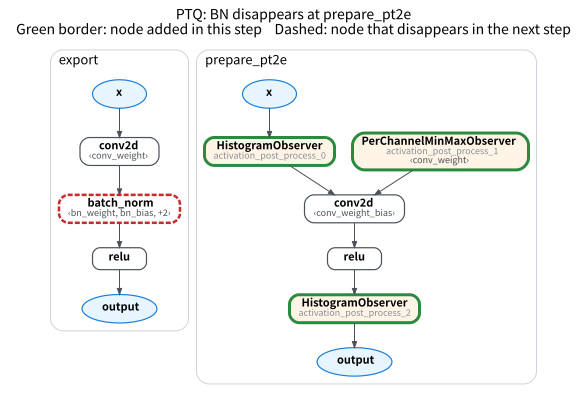

In [3]:
#| echo: false
gm = export_module(model, example_inputs())
prepared = prepare_pt2e(copy.deepcopy(gm), get_xnnpack_quantizer(is_per_channel=True)[0])
draw_stages([(gm, "export"), (prepared, "prepare_pt2e")], title="PTQ: BN disappears at prepare_pt2e")

## Definitions

### BN Folding

An eval-mode BN applies $\mathrm{BN}(y) = \gamma \dfrac{y - \mu}{\sqrt{\sigma^2 + \varepsilon}} + \beta$ to each channel:
$\mu$, $\sigma^2$ are the running mean/var accumulated during training, and $\gamma$, $\beta$ are the BN's weight/bias.
Substituting the conv output $y = W * x + b$ and rearranging gives another conv whose weight and bias are:

$$
W_{\text{fold}} = W \cdot \frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{1}
$$

$$
b_{\text{fold}} = \beta + (b - \mu)\,\frac{\gamma}{\sqrt{\sigma^2+\varepsilon}} \tag{2}
$$

The multiplication is per output channel: all weights of the $k$-th output channel are multiplied by $\gamma_k / \sqrt{\sigma_k^2+\varepsilon}$.
This is only an algebraic rearrangement, so the folded fp32 output equals the original. Computing by hand with the BN parameters of the example above and comparing with what torchao folds:

In [4]:
bn = model.bn
assert bn.running_mean is not None and bn.running_var is not None
k = bn.weight / torch.sqrt(bn.running_var + bn.eps)
w_fold = model.conv.weight * k.reshape(-1, 1, 1, 1)  # Eq. (1)
b_fold = bn.bias - bn.running_mean * k  # Eq. (2); this conv has no bias (b = 0)
same_w = torch.allclose(prepared.get_parameter("conv.weight"), w_fold, atol=1e-6)
same_b = torch.allclose(getattr(prepared.get_submodule("conv"), "weight_bias"), b_fold, atol=1e-6)
print(f"Eq. (1) matches the weight folded by torchao? {same_w}; Eq. (2) matches the bias? {same_b}")
assert same_w and same_b

Eq. (1) matches the weight folded by torchao? True; Eq. (2) matches the bias? True


### PTQ vs. QAT: At Which Step BN Is Folded

| | PTQ (`prepare_pt2e`) | QAT (`prepare_qat_pt2e`) |
|---|---|---|
| BN after prepare | Already folded into conv; gone from the graph | Still there; uses the current batch's statistics during training |
| What the weight quantization sees | The weight folded by Eq. (1) | A separately computed $W \cdot s$ for the fake quant, equal to Eq. (1) |
| When BN is actually folded | Right at the start of prepare, before the Quantizer's `annotate` | At `convert_pt2e` |

Why QAT cannot fold at prepare: during training, BN must normalize with the mean and variance of the **current batch** and also update the running stats.
Folding it would freeze BN into eval mode, and BN would no longer train.

### QAT: Which Weight Should the Weight's Fake Quant Quantize

The reasoning below is adapted from the blog post above, whose original source is Google's quantization whitepaper
(R. Krishnamoorthi, *Quantizing deep convolutional networks for efficient inference: A whitepaper*, 2018).
Here the conv has no bias; $\sigma$ below means the standard deviation with $\varepsilon$ already included, i.e. the $\sqrt{\sigma^2+\varepsilon}$ in the denominator of Eq. (1).

During training BN uses this batch's $\mu_B$, $\sigma_B$; at inference it uses their EMA (running stats) $\mu$, $\sigma$.
So the "folded weight" has two versions:

$$
W_{\text{train}} = \frac{\gamma W}{\sigma_B}, \qquad W_{\text{inf}} = \frac{\gamma W}{\sigma} \tag{3}
$$

$W_{\text{inf}}$ is Eq. (1), the weight actually quantized to int8 at deployment. The weight's fake quant has three candidates:

| What the fake quant quantizes | Problem |
|---|---|
| $W$ (unfolded conv weight) | At deployment $W_{\text{inf}}$ is what gets quantized, so the quantization error seen in training differs from deployment |
| $W_{\text{train}}$ | $\sigma_B$ jumps every batch, so the quantization grid jumps with it; together with the fake quant error, training is unstable (the whitepaper's experiments saw the loss oscillate) |
| $W_{\text{inf}}$ | The EMA changes slowly, and it is the same weight quantized at deployment → **choose this one** |

But during training BN needs the effect of batch statistics. The whitepaper's approach is to quantize $W_{\text{inf}}$ and then multiply by a **correction term** $\sigma / \sigma_B$ to recover $W_{\text{train}}$:

$$
y = \mathrm{conv}\big(\mathrm{fq}(x),\ \mathrm{fq}(W_{\text{inf}})\big) \cdot \frac{\sigma}{\sigma_B} + \Big(\beta - \frac{\gamma\,\mu_B}{\sigma_B}\Big) \tag{4}
$$

The catch is that $\mu_B$, $\sigma_B$ must be computed from the **unquantized** conv output, so every step needs an extra conv. PyTorch implements this as `_forward_slow`; below we call it the **slow version**.

### PyTorch's Approximate Version: This Is What PT2E Uses

PyTorch eager QAT's default `_forward_approximate` saves that extra conv, and the subgraph inserted by `prepare_qat_pt2e` is this one:

$$
s = \frac{\gamma}{\sigma}, \qquad
y = \mathrm{BN}_{\text{batch}}\!\Big( \frac{\mathrm{conv}\big(\mathrm{fq}(x),\ \mathrm{fq}(W \cdot s)\big)}{s} \Big) \tag{5}
$$

- $W \cdot s = \gamma W / \sigma = W_{\text{inf}}$: the fake quant quantizes exactly the one chosen in the table above.
- **Why divide by $s$**: $\mathrm{conv}(\cdot, W_{\text{inf}}) / s$ is approximately the output of the unfolded conv; handing it to the normally training BN lets BN compute batch statistics $\mu_B'$, $\sigma_B'$ from it.
  Expanding BN: $\gamma \dfrac{z/s - \mu_B'}{\sigma_B'} + \beta = z \cdot \dfrac{\sigma}{\sigma_B'} + \Big(\beta - \dfrac{\gamma\,\mu_B'}{\sigma_B'}\Big)$ ($z$ is the output of the quantized conv), which is exactly the form of Eq. (4).
- The only difference: $\mu_B'$, $\sigma_B'$ come from the **quantized** conv output, whereas the slow version takes them from the **unquantized** one. The cost is that quantization error leaks into the batch statistics; the gain is one fewer conv.

M04-2 maps each term of Eq. (5) to a node in the graph, and M04-3 hand-writes both versions to compare the numbers.

## Verify with Code: QAT's BN Disappears Only at convert

The same model through QAT: export with the training IR and a quantizer with `is_qat=True`. BN is still there after prepare and disappears only after convert:

In [5]:
def has_bn(g):
    return any("batch_norm" in str(n.target) for n in g.graph.nodes)


qat_prepared = prepare_qat_pt2e(export_module(copy.deepcopy(model).train(), example_inputs(), train=True),
                                get_xnnpack_quantizer(is_per_channel=True, is_qat=True)[0])
with torch.no_grad():
    qat_prepared(torch.randn(16, 3, 16, 16) * 2 + 1)  # give the fake quant ranges real values
qat_converted = convert_pt2e(copy.deepcopy(qat_prepared))
print(f"QAT: batch_norm after prepare? {has_bn(qat_prepared)}; after convert? {has_bn(qat_converted)}")
assert has_bn(qat_prepared) and not has_bn(qat_converted)

QAT: batch_norm after prepare? True; after convert? False


## Summary and Chapter Map

- PT2E has no fused modules; the fusion of conv + BN is folding BN into the conv's weight and bias (Eq. 1, 2).
- PTQ folds right at the start of `prepare_pt2e`; QAT keeps BN for training, uses Eq. (5) so the fake quant quantizes $W_{\text{inf}}$, and `convert_pt2e` does the real folding.
- After convert the graphs from both paths are the same, so the backend cannot tell the difference.

| notebook | Question it answers |
|---|---|
| [M04-1 BN folding in PTQ](01_bn_folding_trace.ipynb) | At which step BN disappears, how weight and bias are rewritten; what it looks like after convert when there is an extra quantization point between conv and relu |
| [M04-2 conv + BN in QAT](02_qat_graph_structure.ipynb) | Which node in the graph each term of Eq. (5) is, how convert folds, and when folding fails |
| [M04-3 Slow vs. approximate version](03_qat_vs_article.ipynb) | Whether PT2E's subgraph is `_forward_approximate`, and how much it differs from the slow version |

What this chapter deliberately skips: the QAT training flow and when to freeze BN and observers (M06); the pitfall in how `FusedMovingAvgObsFakeQuantize` computes scale (M06-3).

## References

- [Convolution and BatchNorm Fusion](https://bobondemon.github.io/2025/05/04/Convolution-%E8%88%87-BatchNorm-%E7%9A%84%E8%9E%8D%E5%90%88%E5%A4%A7%E6%B3%95/) (in Chinese): derivation of BN folding, how fake quant should be inserted in QAT, PyTorch's slow and approximate versions (read this first)
- R. Krishnamoorthi, [Quantizing deep convolutional networks for efficient inference: A whitepaper](https://arxiv.org/abs/1806.08342), 2018: the correction term $\sigma/\sigma_B$ approach (i.e. the slow version)
- torchao 0.18 source:
  [`utils.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/utils.py) (PTQ's `_fuse_conv_bn_`),
  [`qat_utils.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/qat_utils.py) (QAT's subgraph and the folding at convert)
- PyTorch source: [`conv_fused.py`](https://github.com/pytorch/pytorch/blob/main/torch/ao/nn/intrinsic/qat/modules/conv_fused.py) (eager QAT's `_forward_approximate` and `_forward_slow`)